In [1]:
import numpy as np
import pandas as pd
from IPython.display import display
from pathlib import Path
import matplotlib.pyplot as plt

In [2]:
data_path = Path("../data/processed")

csv_files = list(data_path.glob("*.csv"))

display(csv_files[0].name)

def read_datasets(datasets):
    dataframe = {}
    for dataset in datasets:
        filename = dataset.name
        dataframe[filename] = pd.read_csv(dataset)
    return dataframe

def convert_to_datetime(dataset, columns):
    for column in columns:
        dataset[column] = pd.to_datetime(dataset[column])
    return dataset

orders_dataset_columns_to_datetime = [
    "order_purchase_timestamp", 
    "order_approved_at", 
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date" 
    ]

order_items_dataset_columns_to_datetime = [
    "shipping_limit_date" 
    ]

order_reviews_dataset_columns_to_datetime = [
    "review_creation_date",
    "review_answer_timestamp" 
    ]

datasets = read_datasets(csv_files)

customers_dataset = datasets["olist_customers_dataset.csv"]
geolocation_dataset = datasets["olist_geolocation_dataset.csv"]
order_payments_dataset = datasets["olist_order_payments_dataset.csv"]
products_dataset = datasets["olist_products_dataset.csv"]
sellers_dataset = datasets["olist_sellers_dataset.csv"]
category_translation_dataset = datasets["product_category_name_translation.csv"]

orders_dataset = convert_to_datetime(dataset=datasets["olist_orders_dataset.csv"], columns=orders_dataset_columns_to_datetime)
orders_items_dataset = convert_to_datetime(dataset=datasets["olist_order_items_dataset.csv"], columns=order_items_dataset_columns_to_datetime)
reviews_dataset = convert_to_datetime(dataset=datasets["olist_order_reviews_dataset.csv"], columns=order_reviews_dataset_columns_to_datetime)

display(orders_dataset.dtypes)
display(orders_items_dataset.dtypes)
display(reviews_dataset.dtypes)

'olist_customers_dataset.csv'

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

order_id                          str
order_item_id                   int64
product_id                        str
seller_id                         str
shipping_limit_date    datetime64[us]
price                         float64
freight_value                 float64
dtype: object

review_id                             str
order_id                              str
review_score                        int64
review_comment_title                  str
review_comment_message                str
review_creation_date       datetime64[us]
review_answer_timestamp    datetime64[us]
dtype: object

In [3]:
#How many customers?
display(customers_dataset.head(1))
unique_customers = customers_dataset["customer_unique_id"].nunique()
all_customers = customers_dataset["customer_id"].count()
display(f"Total number of unique customers: {unique_customers}")
display(f"Total number of customers: {all_customers}")

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP


'Total number of unique customers: 96096'

'Total number of customers: 99441'

In [4]:
#How many sellers?
display(sellers_dataset.head(1))
display(len(sellers_dataset["seller_id"]))

number_of_sellers = sellers_dataset["seller_id"].nunique()
display(f"Total number of sellers: {number_of_sellers}")

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP


3095

'Total number of sellers: 3095'

In [5]:
#How many products?
display(products_dataset.head(1))
display(len(products_dataset["product_id"]))

number_of_unique_products = products_dataset["product_id"].nunique()
display(f"Total number of unique products: {number_of_unique_products}")

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0


32951

'Total number of unique products: 32951'

In [6]:
#How many orders?
orders_dataset.head(1)
display(len(orders_dataset["order_id"]))

number_of_orders = orders_dataset["order_id"].nunique()
display(f"Total number of orders: {number_of_orders}")

99441

'Total number of orders: 99441'

In [7]:
#How many reviews?
reviews_dataset.head(1)

display(f"Total number of review_id: {len(reviews_dataset["review_id"])}")

number_of_reviews = reviews_dataset["review_id"].nunique()
display(f"Total number of reviews (unique): {number_of_reviews}")

'Total number of review_id: 99224'

'Total number of reviews (unique): 98410'

In [8]:
orders_dataset["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [9]:
#What proportion of orders are delivered?
def orders_status_percentage(dataset, order_status):
    orders_with_status = dataset[dataset["order_status"] == order_status]
    percentage_of_orders = round((len(orders_with_status) / len(dataset)) * 100, 3)
    return f"Percentage of {order_status} orders is {percentage_of_orders}%"

delivered_orders = display(orders_status_percentage(dataset=orders_dataset, order_status="delivered"))
#What proportion of orders are cancelled?
canceled_orders = display(orders_status_percentage(dataset=orders_dataset, order_status="canceled"))
unavailable_orders = display(orders_status_percentage(dataset=orders_dataset, order_status="unavailable"))

'Percentage of delivered orders is 97.02%'

'Percentage of canceled orders is 0.629%'

'Percentage of unavailable orders is 0.612%'

,Year,Orders,Growth (%)
0,2016,329,NaN
1,2017,45101,13608.51
2,2018,54011,19.76


,Month,Sales 2016,Sales 2017,Sales 2018
0,January,0,800,7269
1,February,0,1780,6728
2,March,0,2682,7211
3,April,0,2404,6939
4,May,0,3700,6873
5,June,0,3245,6167
6,July,0,4026,6292
7,August,0,4331,6512
8,September,4,4285,16
9,October,324,4631,4


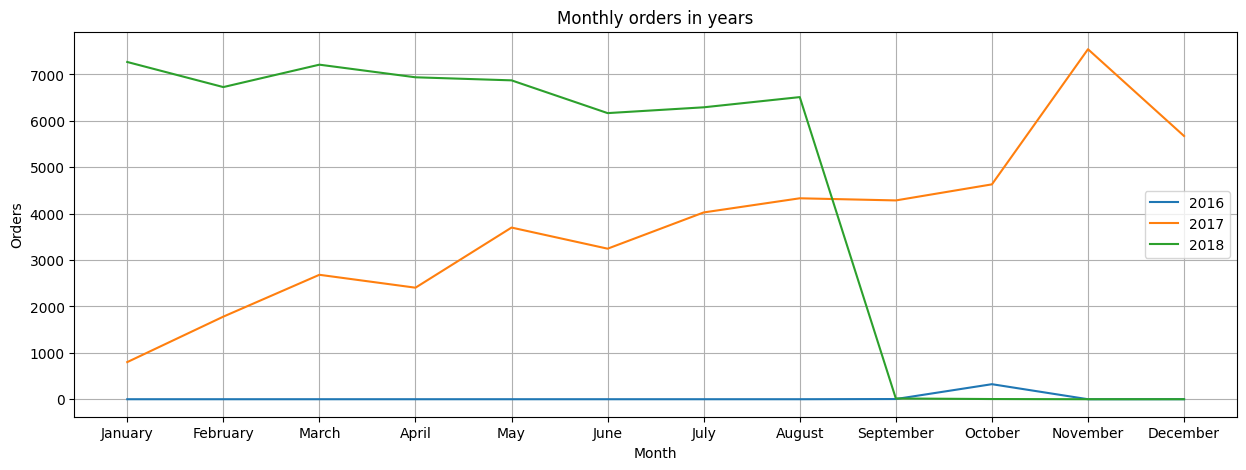

In [10]:
#Is the platform growing?
#Are orders increasing or decreasing?
orders_dataset.head()
orders_dataset.dtypes
orders_purchased_2016 = orders_dataset["order_purchase_timestamp"].dt.year == 2016
orders_purchased_2017 = orders_dataset["order_purchase_timestamp"].dt.year == 2017
orders_purchased_2018 = orders_dataset["order_purchase_timestamp"].dt.year == 2018


yearly_sales = pd.DataFrame(
    {
        "Year": [2016, 2017, 2018],
        "Orders": [
          orders_purchased_2016.sum(),
          orders_purchased_2017.sum(),
          orders_purchased_2018.sum()  
        ]
    }
)

yearly_sales["Growth (%)"] = round(yearly_sales["Orders"].pct_change() * 100, 2)


display(yearly_sales) #Based on this it can be seen that the platform definietely growing 

#Are there seasonal patterns?
#Which months are strongest?
def calculate_monthly_sale(dataset, year):
    monthly_sales = {}
    year_sales = dataset[dataset["order_purchase_timestamp"].dt.year == year]
    for month in range(1, 13):
        monthly_sales[month] = (year_sales["order_purchase_timestamp"].dt.month == month).sum()
    return monthly_sales

monthly_sales_2016 = calculate_monthly_sale(dataset=orders_dataset, year=2016)
monthly_sales_2017 = calculate_monthly_sale(dataset=orders_dataset, year=2017)
monthly_sales_2018 = calculate_monthly_sale(dataset=orders_dataset, year=2018)

pd_monthly_sales = pd.DataFrame(
    {
    "Month": ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"],
    "Sales 2016": monthly_sales_2016.values(),
    "Sales 2017": monthly_sales_2017.values(),
    "Sales 2018": monthly_sales_2018.values()
    }
)

display(pd_monthly_sales)

plt.figure(figsize=(15, 5))

plt.plot(
    pd_monthly_sales["Month"],
    pd_monthly_sales["Sales 2016"],
    label = 2016
)

plt.plot(
    pd_monthly_sales["Month"],
    pd_monthly_sales["Sales 2017"],
    label = 2017
)

plt.plot(
    pd_monthly_sales["Month"],
    pd_monthly_sales["Sales 2018"],
    label = 2018
)

plt.title("Monthly orders in years")
plt.xlabel("Month")
plt.ylabel("Orders")
plt.legend()
plt.grid()

plt.show()



Customers Analysis

'Total number of customer: 99441'

customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
Name: count, dtype: int64

'Top 15 cities by customers: 38839'

'Other cities customers combined: 60602'

sao paulo                15540
rio de janeiro            6882
belo horizonte            2773
brasilia                  2131
curitiba                  1521
campinas                  1444
porto alegre              1379
salvador                  1245
guarulhos                 1189
sao bernardo do campo      938
niteroi                    849
santo andre                797
osasco                     746
santos                     713
goiania                    692
Others                   60602
dtype: int64

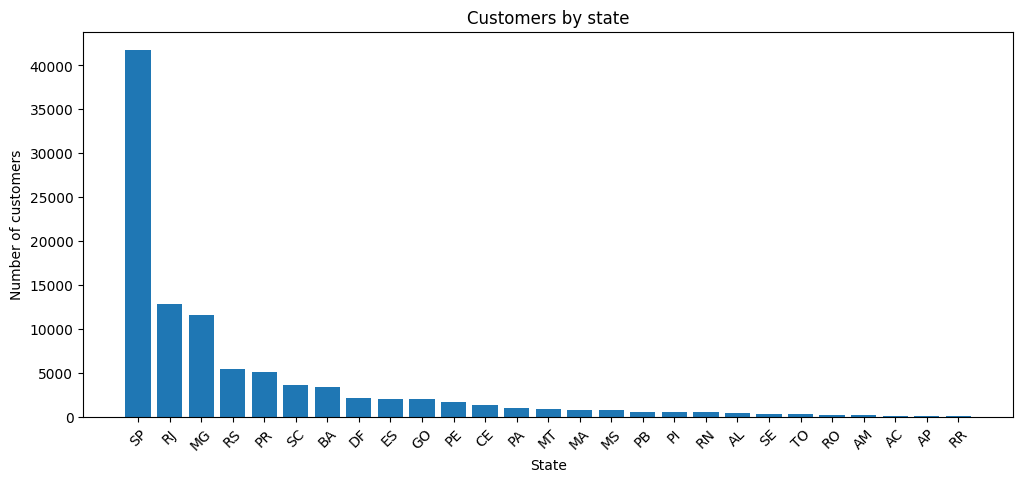

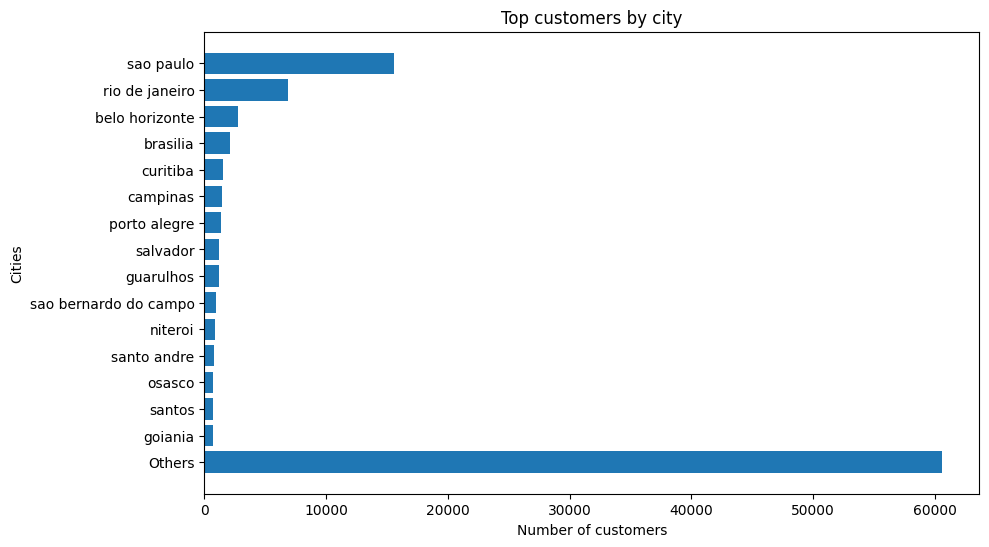

In [11]:
#Where are customers located?
#Which states have the most customers?
#How many customers make repeat purchases?
#Are most customers one-time buyers?

#Where are customers located?
display(f"Total number of customer: {len(customers_dataset)}")
customers_by_state = customers_dataset["customer_state"].value_counts()
display(customers_by_state.head(10))

customers_by_city = customers_dataset["customer_city"].value_counts()
top_15_customers_by_city = customers_by_city.iloc[:15]

display(f"Top 15 cities by customers: {sum(top_15_customers_by_city)}")

others_customers_by_city = pd.Series({
    "Others": customers_by_city.iloc[15:].sum()
})

display(f"Other cities customers combined: {sum(others_customers_by_city)}")

pd_customers_by_city = pd.concat([
    top_15_customers_by_city,
    others_customers_by_city
])

display(pd_customers_by_city)

plt.figure(figsize=(12, 5))
plt.bar(
    customers_by_state.index,
    customers_by_state.values
)

plt.title("Customers by state")
plt.xlabel("State")
plt.ylabel("Number of customers")

plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(10, 6))
plt.barh(pd_customers_by_city.index, pd_customers_by_city.values)
plt.title("Top customers by city")
plt.xlabel("Number of customers")
plt.ylabel("Cities")

plt.gca().invert_yaxis()

plt.show()

In [12]:
len(orders_dataset)

99441

In [13]:
#How many customers make repeat purchases?
#Are most customers one-time buyers?
display(customers_dataset.head(1))
display("Total customer_id")
display(len(customers_dataset["customer_id"]))
display(customers_dataset["customer_id"].duplicated().sum())

display("Total customer_unique_id")
display(len(customers_dataset["customer_unique_id"]))
display(customers_dataset["customer_unique_id"].duplicated(keep=False).sum()) #shows same customers

total_number_of_customers = customers_dataset["customer_unique_id"].nunique()
display("Total number of all customers")
display(total_number_of_customers)

repeated_customers = customers_dataset[customers_dataset["customer_unique_id"].duplicated(keep=False)]
repeated_customers = repeated_customers["customer_unique_id"].value_counts()
display("The number of customers who made more than one purchase is:")
repeated_customers = len(repeated_customers)

percentage_of_repeated_customers = round((repeated_customers / total_number_of_customers) * 100, 2)
display(f"The percentage of repeated customers is: {percentage_of_repeated_customers}%")


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP


'Total customer_id'

99441

np.int64(0)

'Total customer_unique_id'

99441

np.int64(6342)

'Total number of all customers'

96096

'The number of customers who made more than one purchase is:'

'The percentage of repeated customers is: 3.12%'

Understand Products

In [14]:
#Which categories are most popular?
#Which categories generate the most revenue?
#Are a few products driving most sales?
products_dataset.head(1)
category_translation_dataset = datasets["product_category_name_translation.csv"]

#Which categories are most popular?
products_categories = products_dataset["product_category_name"].unique()


#Find which products are not translated
missing_categories = []
for category in products_categories:
    if category not in category_translation_dataset["product_category_name"].values:
        missing_categories.append(category)
print(missing_categories) #SO three categories are missing from tranlsation - nan, 'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'
missing_categories_pd = pd.DataFrame({
    "product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos"],
    "product_category_name_english": ["pc_gamer", "portable kitchen appliances and food preparation devices"]
})

category_translation_dataset_full = pd.concat([category_translation_dataset, missing_categories_pd], ignore_index=True)
display(len(category_translation_dataset))

#Check the products with missing categories
missing_categories_products = products_dataset[products_dataset["product_category_name"].isna()]

[nan, 'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']


71

In [15]:
len(category_translation_dataset_full)
category_translation_dataset_full.tail()
#Which categories are most popular?
products_categories_popularity = products_dataset["product_category_name"].value_counts()
products_categories_popularity.head(15)

product_category_name
cama_mesa_banho                3029
esporte_lazer                  2867
moveis_decoracao               2657
beleza_saude                   2444
utilidades_domesticas          2335
automotivo                     1900
informatica_acessorios         1639
brinquedos                     1411
relogios_presentes             1329
telefonia                      1134
bebes                           919
perfumaria                      868
papelaria                       849
fashion_bolsas_e_acessorios     849
cool_stuff                      789
Name: count, dtype: int64

Understand Sellers

In [16]:
#Where are sellers located?
#Which sellers generate the most sales?
#Are sales concentrated among a few sellers?
sellers_dataset.head(1)

#Where are sellers located?
sellers_states = sellers_dataset["seller_state"].value_counts().head(10)
sellers_cities = sellers_dataset["seller_city"].value_counts().head(10)
display(sellers_states)
display(sellers_cities)
# most of the selelrs are located in SP state and in sao paulo city


seller_state
SP    1849
PR     349
MG     244
SC     190
RJ     171
RS     129
GO      40
DF      30
ES      23
BA      19
Name: count, dtype: int64

seller_city
sao paulo         694
curitiba          127
rio de janeiro     96
belo horizonte     68
ribeirao preto     52
guarulhos          50
ibitinga           49
santo andre        45
campinas           41
maringa            40
Name: count, dtype: int64

In [17]:
orders_with_itme_id_1 = orders_items_dataset[orders_items_dataset["order_item_id"] == 1]
orders_with_itme_id_1["order_id"].duplicated().sum()

np.int64(0)

In [18]:
display(orders_items_dataset.shape)
display(orders_dataset.shape)
## they have different number of rows, lets check why

display(orders_dataset["order_id"].duplicated(keep=False).sum()) #no repeated orders, all orders are unique by "order_id"
display(f"Number of orders with more than 1 items: {orders_items_dataset["order_id"].duplicated(keep=False).sum()}") #13984 repeated orders by order_id, lets check why they are repeated
orders_items_dataset_repeated_orders = orders_items_dataset[orders_items_dataset["order_id"].duplicated(keep=False)] 
orders_items_dataset_repeated_orders["order_item_id"].value_counts()
display(orders_items_dataset_repeated_orders[orders_items_dataset_repeated_orders["order_id"] == "00143d0f86d6fbd9f9b38ab440ac16f5"])

display(orders_dataset[orders_dataset["order_id"] == "00143d0f86d6fbd9f9b38ab440ac16f5"])


(112650, 7)

(99441, 8)

np.int64(0)

'Number of orders with more than 1 items: 23787'

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
32,00143d0f86d6fbd9f9b38ab440ac16f5,1,e95ee6822b66ac6058e2e4aff656071a,a17f621c590ea0fab3d5d883e1630ec6,2017-10-20 16:07:52,21.33,15.1
33,00143d0f86d6fbd9f9b38ab440ac16f5,2,e95ee6822b66ac6058e2e4aff656071a,a17f621c590ea0fab3d5d883e1630ec6,2017-10-20 16:07:52,21.33,15.1
34,00143d0f86d6fbd9f9b38ab440ac16f5,3,e95ee6822b66ac6058e2e4aff656071a,a17f621c590ea0fab3d5d883e1630ec6,2017-10-20 16:07:52,21.33,15.1


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
36265,00143d0f86d6fbd9f9b38ab440ac16f5,2e45292979b9b2700ea09560eeb0f803,delivered,2017-10-16 15:29:43,2017-10-16 16:07:52,2017-10-16 23:04:43,2017-10-27 18:43:56,2017-11-06


In [19]:
#Determine number of orders by sellers?
display(orders_dataset.head(1))
display(orders_items_dataset.head(1))

unique_orders = orders_items_dataset.drop_duplicates(subset=["order_id", "seller_id"])
top_sellers_by_number_of_orders = unique_orders["seller_id"].value_counts()
number_orders_by_top_15_sellers = top_sellers_by_number_of_orders.head(15).sum()
display(f"Percentage of orders by top 15 of sellers: {round((number_orders_by_top_15_sellers / unique_orders["order_id"].count()) * 100, 2)}%")
orders_items_dataset.groupby("order_id")["seller_id"].nunique().sort_values(ascending=False)

#orders_items_dataset[orders_items_dataset["order_id"] == "1c11d0f4353b31ac3417fbfa5f0f2a8a"] #so each order can have multiple sellers


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29


'Percentage of orders by top 15 of sellers: 18.19%'

order_id
1c11d0f4353b31ac3417fbfa5f0f2a8a    5
cf5c8d9f52807cb2d2f0a0ff54c478da    5
91be51c856a90d7efe86cf9d082d6ae3    4
1d23106803c48c391366ff224513fb7f    4
8c2b13adf3f377c8f2b06b04321b0925    4
                                   ..
fff1e3e76b816bfe8ef16678cc53c643    1
fff2cdc825f9fc0ba3c04227cfa02303    1
fff2e9e3aa8644e19710216b4ef53ab2    1
fff3983dfa3c5a0d752d8d17baa406a0    1
fffe41c64501cc87c801fd61db3f6244    1
Name: seller_id, Length: 98666, dtype: int64

Calculate revenue

In [20]:
#Calculate total revenue
total_revenue = order_payments_dataset["payment_value"].sum()
display(total_revenue)

#Calculate products revenue
total_products_revenue = orders_items_dataset["price"].sum()
display(total_products_revenue)

#Calculate total freight revenue
total_freight_revenue = orders_items_dataset["freight_value"].sum()
display(total_freight_revenue)

revenue_check = total_products_revenue + total_freight_revenue
display(revenue_check)

#There is a differnce in the revenue, where total revenue from order_payment_dataset is bigger than from the orders_items_dataset
display(f"The difference is {total_revenue - revenue_check}")


np.float64(16008872.120000001)

np.float64(13591643.7)

np.float64(2251909.54)

np.float64(15843553.239999998)

'The difference is 165318.88000000268'

In [21]:
display(order_payments_dataset.head(1))
display(orders_items_dataset.head(1))

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29


In [22]:
#Merge order_payment_dataset with orders_dataset to check the orders status
merged_order_status_payment = pd.merge(
    order_payments_dataset,
    orders_dataset[["order_id", "order_status"]],
    on="order_id",
    how="left"
)

In [23]:
merged_order_status_payment.groupby("order_status")["order_id"].nunique().sort_values(ascending=False)

order_status
delivered      96477
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: order_id, dtype: int64

In [24]:
#Check if there are duplicated order_id in payment dataset
display(len(order_payments_dataset))
display(len(merged_order_status_payment))

merged_order_status_payment["order_id"].duplicated(keep=False).sum() #there are 4446 duplicated order_id in payment dataset

103886

103886

np.int64(7407)

In [25]:
#Why there are duplicated order_id in payment dataset
merged_order_status_payment_duplicated = merged_order_status_payment[merged_order_status_payment["order_id"].duplicated(keep=False)]
merged_order_status_payment_duplicated["order_id"].value_counts() #lets explore one order_id that has 29 entries in payment and see why?
merged_order_status_payment_duplicated[merged_order_status_payment_duplicated["order_id"] == "fa65dad1b0e818e3ccc5cb0e39231352"]

#Now lets try to find hte same order_id in order_id and order_items_id to see if its also duplicated in there 
orders_items_dataset[orders_items_dataset["order_id"] == "fa65dad1b0e818e3ccc5cb0e39231352"] #its not duplicated, only one entry
orders_dataset[orders_dataset["order_id"] == "fa65dad1b0e818e3ccc5cb0e39231352"] #also not duplicated

#Now lets compare the prices in both dataset if they are equal
display(merged_order_status_payment_duplicated[merged_order_status_payment_duplicated["order_id"] == "fa65dad1b0e818e3ccc5cb0e39231352"]["payment_value"].sum())
display(orders_items_dataset[orders_items_dataset["order_id"] == "fa65dad1b0e818e3ccc5cb0e39231352"]["price"]
        + orders_items_dataset[orders_items_dataset["order_id"] == "fa65dad1b0e818e3ccc5cb0e39231352"]["freight_value"]) #they are identical

np.float64(457.99)

110202    457.99
dtype: float64

In [26]:
merged_orders_items_status = pd.merge(
    left=orders_items_dataset,
    right=orders_dataset[["order_id", "order_status"]],
    on="order_id",
    how="left"
)

In [27]:
merged_orders_items_status.groupby("order_status")["order_id"].nunique().sort_values(ascending=False)

order_status
delivered      96478
shipped         1106
canceled         461
invoiced         312
processing       301
unavailable        6
approved           2
Name: order_id, dtype: int64

In [28]:
#Check how many duplicated order_id in order_items dataset
display(len(orders_items_dataset))
display(len(merged_orders_items_status))

merged_orders_items_status["order_id"].duplicated(keep=False).sum() #there are 23787 duplicated order_id in orders_items_dataset

112650

112650

np.int64(23787)

Clearly there is a revenue difference between order_items dataset and order_payment dataset, this is potentially to the different amopunt of order_id in both datasets, now need to investigate why there is order_id difference.

In [29]:
#First let establish again the unqiue number of order_id in both orders_dataset, orders_items_dataset and order_payments_dataset
display(f"The number of unique order_id in orders_dataset: {orders_dataset.groupby("order_id")["order_id"].nunique().sum()}")
display(f"The number of unique order_id in orders_items_dataset: {orders_items_dataset.groupby("order_id")["order_id"].nunique().sum()}")
display(f"The number of unique order_id in orders_payment_dataset: {order_payments_dataset.groupby("order_id")["order_id"].nunique().sum()}")



'The number of unique order_id in orders_dataset: 99441'

'The number of unique order_id in orders_items_dataset: 98666'

'The number of unique order_id in orders_payment_dataset: 99440'

In [30]:
#Clearly there is different number of order_id in different datasets, lets explore which datasets are missing
orders_without_payment = (
    set(orders_dataset["order_id"]) - set(order_payments_dataset["order_id"])
)
len(orders_without_payment)

display(orders_without_payment)

orders_dataset[orders_dataset["order_id"].isin(orders_without_payment)]

#So there is one order which is delivered but somehow missing the payment record - lets investigate whether this order is presemtin order_items
orders_without_payment = orders_items_dataset[orders_items_dataset["order_id"].isin(orders_without_payment)]
#So since that order is delivered and has items and items prices we can calculate payment from the items dataset and megre to the payment table
total_revenue = (orders_without_payment["price"].sum() + orders_without_payment["freight_value"].sum() + order_payments_dataset["payment_value"].sum())
display(f"Total revenue from order_payments dataset: {total_revenue}")


{'bfbd0f9bdef84302105ad712db648a6c'}

'Total revenue from order_payments dataset: 16009015.580000002'

In [31]:
#Now lets check the missing order_id in order_items_dataset
orders_without_items = set(orders_dataset["order_id"]) - set(orders_items_dataset["order_id"])
orders_without_items_complete = orders_dataset[orders_dataset["order_id"].isin(orders_without_items)]
display(orders_without_items_complete["order_status"].value_counts())
orders_without_items_complete
#display(orders_without_items_complete["payment_value"])
#Most of the orders have missing items because their order status is unavailable or cancelled

order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
266,8e24261a7e58791d10cb1bf9da94df5c,64a254d30eed42cd0e6c36dddb88adf0,unavailable,2017-11-16 15:09:28,2017-11-16 15:26:57,NaT,NaT,2017-12-05
586,c272bcd21c287498b4883c7512019702,9582c5bbecc65eb568e2c1d839b5cba1,unavailable,2018-01-31 11:31:37,2018-01-31 14:23:50,NaT,NaT,2018-02-16
687,37553832a3a89c9b2db59701c357ca67,7607cd563696c27ede287e515812d528,unavailable,2017-08-14 17:38:02,2017-08-17 00:15:18,NaT,NaT,2017-09-05
737,d57e15fb07fd180f06ab3926b39edcd2,470b93b3f1cde85550fc74cd3a476c78,unavailable,2018-01-08 19:39:03,2018-01-09 07:26:08,NaT,NaT,2018-02-06
1130,00b1cb0320190ca0daa2c88b35206009,3532ba38a3fd242259a514ac2b6ae6b6,canceled,2018-08-28 15:26:39,NaT,NaT,NaT,2018-09-12
...,...,...,...,...,...,...,...,...
99252,aaab15da689073f8f9aa978a390a69d1,df20748206e4b865b2f14a5eabbfcf34,unavailable,2018-01-16 14:27:59,2018-01-17 03:37:34,NaT,NaT,2018-02-06
99283,3a3cddda5a7c27851bd96c3313412840,0b0d6095c5555fe083844281f6b093bb,canceled,2018-08-31 16:13:44,NaT,NaT,NaT,2018-10-01
99347,a89abace0dcc01eeb267a9660b5ac126,2f0524a7b1b3845a1a57fcf3910c4333,canceled,2018-09-06 18:45:47,NaT,NaT,NaT,2018-09-27
99348,a69ba794cc7deb415c3e15a0a3877e69,726f0894b5becdf952ea537d5266e543,unavailable,2017-08-23 16:28:04,2017-08-28 15:44:47,NaT,NaT,2017-09-15


In [32]:
#Now lets check if the missing items orders are present in the payment dataset
orders_without_items_complete = order_payments_dataset[order_payments_dataset["order_id"].isin(orders_without_items)]
display(orders_without_items_complete["order_id"].nunique())
not_included_revenue = round(orders_without_items_complete["payment_value"].sum(), 2)
display(not_included_revenue)
#Based on this we can make a conclusion that these orders had payments at first but then probably got cancelled and not delivered, hence why there are items missing.

775

np.float64(162591.95)

In [33]:
#So for total revenue calculation we will remove the orders with the missing items
total_revenue = (orders_without_payment["price"].sum() + orders_without_payment["freight_value"].sum() + order_payments_dataset["payment_value"].sum() - not_included_revenue)
display(f"Total revenue from order_payments dataset: {round(total_revenue, 2)}")

'Total revenue from order_payments dataset: 15846423.63'

Analyze Delivery Performance

In [34]:
#How long does delivery take?
#Are deliveries usually on time?
#Which regions have slower delivery?
#How often are deliveries late?

In [35]:
#How long does delivery take?
#We will only consider the delivered status orders
delivered_orders = orders_dataset[orders_dataset["order_status"] == "delivered"]
delivered_orders["order_status"].value_counts()
display(f"Percentage of delivered orders is: {round((len(delivered_orders) / len(orders_dataset)) * 100, 2)}%")
display(delivered_orders.head(1))

delivery_time = (delivered_orders["order_delivered_customer_date"] - delivered_orders["order_purchase_timestamp"])
delivery_days = delivery_time.dt.days

display(delivery_days.describe())

'Percentage of delivered orders is: 97.02%'

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18


count    96470.000000
mean        12.093604
std          9.551380
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max        209.000000
dtype: float64

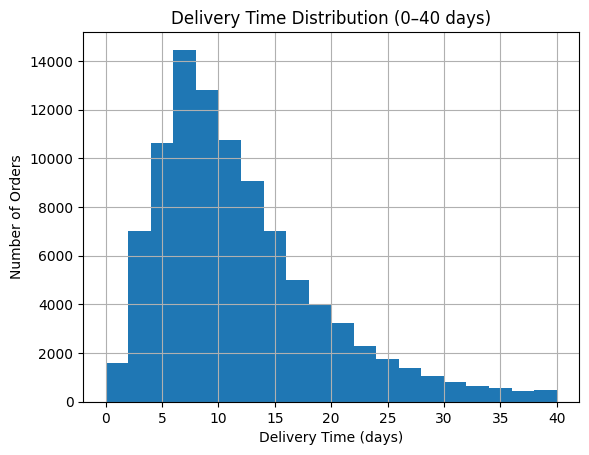

In [36]:
delivery_days[delivery_days <= 40].hist(bins=20)

plt.xlabel("Delivery Time (days)")
plt.ylabel("Number of Orders")
plt.title("Delivery Time Distribution (0–40 days)")
plt.show()

In [37]:
#Are deliveries usually on time?
#How often are deliveries late?
display(len(delivered_orders))
late_delivery = (delivered_orders["order_delivered_customer_date"] > delivered_orders["order_estimated_delivery_date"])
late_orders = (delivered_orders[late_delivery])
late_orders.count() #7826 orders were delivered past the estimated delivery date

#Calculate the percentage of late orders
late_delivery_percentage = round(late_delivery.mean() * 100, 2)
display(f"The percentage of late delivered orders is: {late_delivery_percentage}%")

#Calculate the average amount of time of order being late
late_delivery_time = (late_orders["order_delivered_customer_date"] - late_orders["order_estimated_delivery_date"])
average_late_delivery_time = late_delivery_time.dt.total_seconds().mean() / 86400
display(f"Average late delivery time is: {round(average_late_delivery_time, 2)} days")

96478

'The percentage of late delivered orders is: 8.11%'

'Average late delivery time is: 9.55 days'

In [38]:
#Which regions have slower delivery?
#First need to try to merge the orders with the region information
display(delivered_orders.head(1))
display(customers_dataset.head(1))
#So lets assume that the order placed by the customer will be delivered to the customer city adn customer state where the customer infromation is placed
#Lets check again if the customer_id in the orders_dataset is repeated
orders_customers_merged = pd.merge(
    left=delivered_orders,
    right=customers_dataset[["customer_id", "customer_zip_code_prefix", "customer_city", "customer_state"]],
    on="customer_id",
    how="left",
    indicator=True
)

display(orders_customers_merged["_merge"].value_counts())
orders_customers_merged.head()

orders_customers_merged["total_delivery_time"] = orders_customers_merged["order_delivered_customer_date"] - orders_customers_merged["order_purchase_timestamp"]
orders_customers_merged.head(1)

state_delivery = orders_customers_merged.groupby("customer_state")["total_delivery_time"].mean().sort_values(ascending=False)
display(state_delivery)
city_delivery = orders_customers_merged.groupby("customer_city")["total_delivery_time"].mean().sort_values(ascending=False)
display(city_delivery.head(20))

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP


_merge
both          96478
left_only         0
right_only        0
Name: count, dtype: int64

customer_state
RR   29 days 09:18:03.975609
AP   27 days 04:26:29.850746
AM   26 days 10:13:25.613793
AL   24 days 13:03:09.103274
PA   23 days 18:33:00.021141
MA   21 days 13:45:05.167364
SE   21 days 12:28:29.707462
CE   21 days 06:23:52.394057
AC   21 days 00:51:25.600000
PB   20 days 10:14:32.721470
PI   19 days 10:58:13.289915
RO   19 days 08:55:43.954732
BA   19 days 08:03:04.247235
RN   19 days 06:40:32.696202
PE   18 days 10:45:35.106716
MT   18 days 01:20:17.319413
TO   17 days 15:47:36.609489
ES   15 days 18:56:36.134335
MS   15 days 14:50:22.763195
GO   15 days 14:33:07.649463
RJ   15 days 07:25:35.403643
RS   15 days 07:12:23.863023
SC   14 days 22:54:53.240552
DF   12 days 23:13:17.884615
MG   12 days 00:12:28.711819
PR   11 days 23:47:52.704448
SP    8 days 18:16:23.750061
Name: total_delivery_time, dtype: timedelta64[us]

customer_city
novo brasil                  148 days 04:11:17
capinzal do norte     109 days 01:48:02.500000
adhemar de barros             97 days 11:14:39
arace                  86 days 09:41:40.750000
marcelino vieira              78 days 04:22:39
serra dos dourados            74 days 16:11:40
aramari                       73 days 15:51:50
humildes                      71 days 12:29:46
santa cruz de goias           67 days 14:00:39
machadinho                    65 days 18:59:54
rubineia                      63 days 20:17:51
alto sao joao                 59 days 00:57:38
glaura                        58 days 15:28:06
ourem                         57 days 09:31:00
santaluz                      57 days 06:18:09
placas                 56 days 08:30:52.500000
felicio dos santos            54 days 20:33:51
assuncao                      52 days 23:21:39
conceicao da feira            52 days 05:35:59
boa vista do gurupi           52 days 02:12:57
Name: total_delivery_time, dtype: timedelta64[

Analyze Reviews

In [39]:
#What is the average review score?
#How are ratings distributed?
#What causes poor reviews?
#Do late deliveries lead to lower ratings?

review_score
5    57.776344
4    19.291704
3     8.242965
2     3.175643
1    11.513344
Name: proportion, dtype: float64

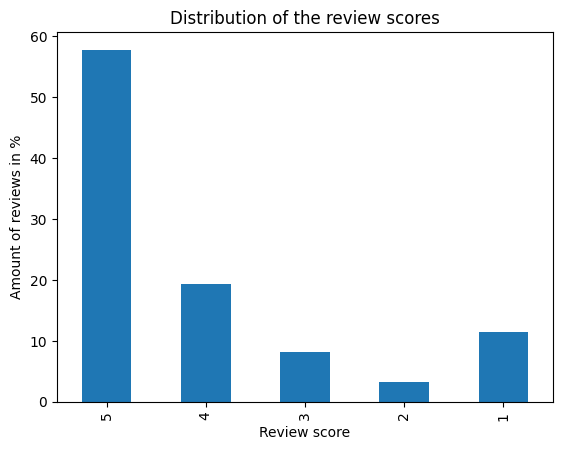

In [40]:
#What is the average review score?
average_review_score = reviews_dataset["review_score"].mean()
average_review_score

#How are ratings distributed?
reviews_dataset.head()
reviews_distribution = reviews_dataset["review_score"].value_counts(normalize=True).sort_index(ascending=False) * 100
display(reviews_distribution)

reviews_distribution.plot(kind="bar")
plt.xlabel("Review score")
plt.ylabel("Amount of reviews in %")
plt.title("Distribution of the review scores")
plt.show()

#Based on this distributionw e can see that the majority (57.7%) of reviews are excellent meaning 5/5, while 4/5 are also sizable (19.2%).
#Although surprisingly 1/5 score reviews are also quite big (11.5%) - need to analyze what is the reason for such low scores

In [ ]:
#What causes poor reviews?
one_point_reviews = reviews_dataset[reviews_dataset["review_score"] == 1]

#Lets analyze how many of these reviews have review_comment_title
one_point_reviews_title = one_point_reviews["review_comment_title"]
one_point_reviews_title_count_not_na = (
    one_point_reviews["review_comment_title"].notna().sum()
)
one_point_reviews_title_count_not_na_percentage = round((one_point_reviews_title_count_not_na / len(one_point_reviews_title)) * 100, 2)
one_point_reviews_title_count_not_na_percentage #only 16.4% of 1 reviews scores have review title

#Lets analyze how many of these reviews have review_message
one_point_reviews_message = one_point_reviews["review_comment_message"]
one_point_reviews_message_count_not_na = (
    one_point_reviews["review_comment_message"].notna().sum()
)
one_point_reviews_message_count_not_na_percentage = round((one_point_reviews_message_count_not_na / len(one_point_reviews_message)) * 100, 2)
one_point_reviews_message_count_not_na_percentage #76.55% of 1 star reviews have comments, I think its important to explore what these comments say

one_point_reviews_message = one_point_reviews_message[one_point_reviews["review_comment_message"].notna()]
one_point_reviews_message.count()



np.int64(8745)

In [44]:
reviews_dataset.head(1)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18,2018-01-18 21:46:59


Analyze Payments

In [42]:
#Which payment methods are most common?
#Are installments heavily used?
#Do higher-value orders use different payment methods?

Connect Everything

In [43]:
#Delivery vs Reviews
#Do delayed deliveries receive worse ratings?
#Product Category vs Reviews
#Are some categories rated more poorly?
#Order Value vs Review Score
#Are expensive purchases reviewed differently?
#Customer Location vs Delivery Time
#Does geography affect customer experience?